# **2.1 Import and Prepration**

### 1. Data Import

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

In [7]:
data = pd.read_csv("housing.csv")
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Seprate Target column and features

In [8]:
X = data.drop("median_house_value", axis=1)
y = data["median_house_value"]

## 2. Handle Outliners
before ant deletion on outliners we should analyse and check distribiution on terget column

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64


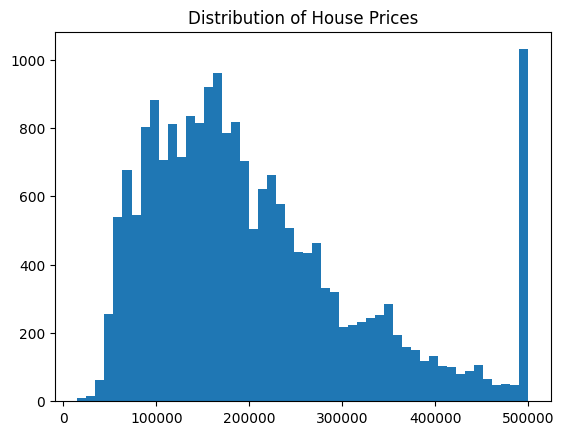

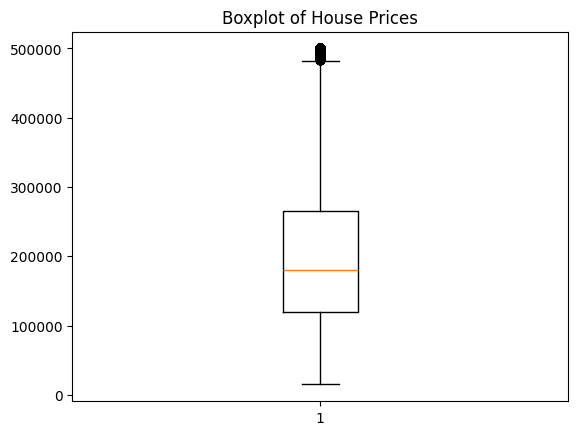

In [9]:
print(y.describe())

plt.hist(y, bins=50)
plt.title("Distribution of House Prices")
plt.show()


plt.boxplot(y)
plt.title("Boxplot of House Prices")
plt.show()

## Target Variable Analysis and Outlier Handling

The distribution of the target variable (median_house_value) was analyzed using histograms and boxplots. The results revealed a strong right-skewed distribution with a noticeable concentration of values around **500,000**, indicating right-censoring in the dataset. These high values represent valid expensive houses rather than measurement errors.

Removing these observations would introduce bias and reduce the model’s ability to learn patterns in higher-priced regions. However, since the neural network is trained using **Mean Squared Error (MSE)** loss, extreme values could disproportionately influence the optimization process due to squared residual amplification.

To address this issue without discarding valuable data, a logarithmic transformation was applied to the target variable:

$$
y_{\text{log}} = \log(1 + y)
$$

This transformation:

- Reduces skewness  
- Compresses large values  
- Stabilizes variance  
- Improves training stability  

The neural network was trained to predict the log-transformed prices. After generating predictions, outputs were converted back to the original scale using the inverse exponential transformation:

$$
y = e^{y_{\text{pred}}} - 1
$$

This approach preserves all observations while ensuring robust and stable regression performance.

In [10]:
y_log = np.log1p(y)

## 3. Split Data
80% train and 10% test and 10% Validation

In [16]:
# 80% train, 20% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_log, test_size=0.2, random_state=4
)

# temp -> 10% val, 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=4
)

## 4. Handle Missing Values

In [17]:
print("Train missing:\n", X_train.isnull().sum())
print("Val missing:\n", X_val.isnull().sum())
print("Test missing:\n", X_test.isnull().sum())

Train missing:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        161
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64
Val missing:
 longitude              0
latitude               0
housing_median_age     0
total_rooms            0
total_bedrooms        25
population             0
households             0
median_income          0
ocean_proximity        0
dtype: int64
Test missing:
 longitude              0
latitude               0
housing_median_age     0
total_rooms            0
total_bedrooms        21
population             0
households             0
median_income          0
ocean_proximity        0
dtype: int64


As we check we have missing values on total_bedrooms feature. The strategy is median cause we may have outliner, So meadian is rubost to outliners.


In [18]:
imputer = SimpleImputer(strategy="median")

num_cols = X_train.select_dtypes(include=["int64","float64"]).columns

X_train[num_cols] = imputer.fit_transform(X_train[num_cols])
X_val[num_cols]   = imputer.transform(X_val[num_cols])
X_test[num_cols]  = imputer.transform(X_test[num_cols])

## 5. Handeling categorical values

### Categorical Feature Encoding

The dataset contains one categorical feature, ocean_proximity. The unique categories were identified using the "value_counts()" function and included values such as INLAND, NEAR BAY, NEAR OCEAN, 1H OCEAN, and ISLAND.

Since neural networks require numerical input and the categorical values have no inherent ordinal relationship, one-hot encoding was applied. This method creates a binary indicator column for each category, avoiding artificial ordering.

The encoding was applied separately to the training and test sets, followed by column alignment to ensure consistent feature representation across both datasets.

In [19]:
X_train = pd.get_dummies(X_train, columns=["ocean_proximity"])
X_val   = pd.get_dummies(X_val, columns=["ocean_proximity"])
X_test  = pd.get_dummies(X_test, columns=["ocean_proximity"])

# aligning columns 
X_train, X_val  = X_train.align(X_val, join="left", axis=1, fill_value=0)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

In [21]:
print(X_train)

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
4520     -118.20     34.04                18.0        796.0           227.0   
29       -122.28     37.84                52.0        729.0           160.0   
7341     -118.14     33.97                29.0       1846.0           530.0   
1067     -121.85     39.73                52.0        444.0            80.0   
5084     -118.29     33.98                46.0       1118.0           300.0   
...          ...       ...                 ...          ...             ...   
16840    -122.46     37.63                22.0       6728.0          1382.0   
11863    -121.24     40.31                36.0       1597.0           301.0   
17093    -122.23     37.48                38.0       1578.0           399.0   
8366     -118.35     33.97                26.0       3832.0          1074.0   
17530    -121.89     37.35                48.0       1562.0           439.0   

       population  households  median_income  ocean

### As we know Neural Network is sensetive to scaling, so scaling is necessery:

In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

# **2.2 Simple Neural Network**

## Conversion to PyTorch Tensors

After completing preprocessing steps (imputation, one-hot encoding, and feature scaling), the data was converted into PyTorch tensors in order to be used as input for the neural network.

Neural networks in PyTorch operate on tensor objects rather than pandas DataFrames or NumPy arrays. Therefore, the feature matrices were converted to float32 tensors, and the target variables were reshaped into column vectors using .view(-1, 1) to match the output dimension of the network (one predicted value per sample).

This step ensures compatibility with PyTorch’s computational framework and enables efficient gradient-based optimization during training.

In [23]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val.to_numpy(), dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32).view(-1, 1)

## Data Loading and Mini-Batch Preparation

To train the neural network efficiently, the datasets were wrapped into TensorDataset objects and loaded using PyTorch’s DataLoader.

A batch size of 64 was used, meaning that the model processes 64 samples at a time during each training step. Mini-batch training improves computational efficiency and stabilizes gradient updates compared to using the entire dataset at once.

Shuffling was enabled for the training set to ensure better generalization and prevent the model from learning patterns related to data ordering. Validation and test sets were not shuffled, since they are used only for evaluation.


In [25]:
batch_size = 64

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)

A simple feed-forward neural network was implemented using PyTorch. The input size was determined based on the number of features in the training data.

The model consists of one hidden layer with 8 neurons followed by a ReLU activation function. The final layer has one neuron that outputs a single value corresponding to the predicted (log-transformed) house price.

This architecture is designed as a baseline regression model to learn the relationship between housing features and price.

In [26]:
input_size = X_train_t.shape[1]

class SimpleNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.net(x)

model = SimpleNN(input_size)

To determine the complexity of the neural network, the total number of trainable parameters was calculated. This includes all weights and bias terms from both linear layers in the model.

The total number of parameters depends on the input size and follows the formula:

Total Parameters = (input_size × 8 + 8) + (8 × 1 + 1)

This computation helps quantify the model capacity and provides insight into how many values are being optimized during training.

In [14]:
total_params = sum(p.numel() for p in model.parameters())
print("input_size =", input_size)
print("Total Parameters =", total_params)

input_size = 13
Total Parameters = 121


In [27]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)  

A learning rate of 0.001 was chosen to ensure smooth and reliable training.

A training loop was implemented to manage both the training and validation processes in a structured way. The run_epoch function performs one full pass over a given dataset. When train=True, the model is set to training mode, gradients are computed, and the optimizer updates the model parameters. When train=False, the model is set to evaluation mode and gradients are disabled to improve efficiency.

For each batch, predictions are generated, the loss is computed using MSE, and the total loss is accumulated. At the end of each epoch, the average loss over the entire dataset is returned.

The model was trained for 30 epochs. After each epoch, both training and validation losses were calculated to monitor learning behavior and detect possible overfitting or underfitting.

In [28]:
def run_epoch(loader, train=False):
    model.train() if train else model.eval()
    total_loss = 0.0

    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            pred = model(xb)
            loss = criterion(pred, yb)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * xb.size(0)

    return total_loss / len(loader.dataset)

epochs = 30
for epoch in range(1, epochs+1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss   = run_epoch(val_loader, train=False)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f}")

Epoch 01 | Train Loss: 123.91816 | Val Loss: 97.79093
Epoch 05 | Train Loss: 9.71086 | Val Loss: 7.89975
Epoch 10 | Train Loss: 0.83264 | Val Loss: 0.65469
Epoch 15 | Train Loss: 0.23679 | Val Loss: 0.23539
Epoch 20 | Train Loss: 0.15176 | Val Loss: 0.15573
Epoch 25 | Train Loss: 0.11140 | Val Loss: 0.11476
Epoch 30 | Train Loss: 0.10184 | Val Loss: 0.10777


In [29]:
test_loss = run_epoch(test_loader, train=False)
print("Test MSE (log scale):", test_loss)

Test MSE (log scale): 0.1029174024051474


# **2.3 Train Simple Neural Network**

The model was trained for 60 epochs using a mini-batch training approach. During each epoch, the network was first set to training mode. For every batch in the training set, predictions were generated, the loss was computed using MSE, gradients were calculated through backpropagation, and the optimizer updated the model parameters.

After completing the training phase of each epoch, the model was switched to evaluation mode to compute the validation loss. Gradient computation was disabled during validation to improve efficiency and prevent parameter updates.

Both training and validation losses were recorded at every epoch. This allowed monitoring of the learning process over time and helped assess whether the model was improving, overfitting, or underfitting.

In [30]:
train_losses = []
val_losses = []

epochs = 60

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    
    for xb, yb in train_loader:
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * xb.size(0)
    
    train_loss = running_train_loss / len(train_loader.dataset)
    
    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            pred = model(xb)
            loss = criterion(pred, yb)
            running_val_loss += loss.item() * xb.size(0)
    
    val_loss = running_val_loss / len(val_loader.dataset)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 01 | Train Loss: 0.1004 | Val Loss: 0.1079
Epoch 02 | Train Loss: 0.0990 | Val Loss: 0.1052
Epoch 03 | Train Loss: 0.0979 | Val Loss: 0.1045
Epoch 04 | Train Loss: 0.0964 | Val Loss: 0.1058
Epoch 05 | Train Loss: 0.0959 | Val Loss: 0.1038
Epoch 06 | Train Loss: 0.0952 | Val Loss: 0.1047
Epoch 07 | Train Loss: 0.0946 | Val Loss: 0.1017
Epoch 08 | Train Loss: 0.0938 | Val Loss: 0.1035
Epoch 09 | Train Loss: 0.0932 | Val Loss: 0.1013
Epoch 10 | Train Loss: 0.0929 | Val Loss: 0.1008
Epoch 11 | Train Loss: 0.0922 | Val Loss: 0.1014
Epoch 12 | Train Loss: 0.0919 | Val Loss: 0.0981
Epoch 13 | Train Loss: 0.0918 | Val Loss: 0.0995
Epoch 14 | Train Loss: 0.0915 | Val Loss: 0.0990
Epoch 15 | Train Loss: 0.0912 | Val Loss: 0.0985
Epoch 16 | Train Loss: 0.0908 | Val Loss: 0.0974
Epoch 17 | Train Loss: 0.0908 | Val Loss: 0.0964
Epoch 18 | Train Loss: 0.0902 | Val Loss: 0.0960
Epoch 19 | Train Loss: 0.0900 | Val Loss: 0.0966
Epoch 20 | Train Loss: 0.0898 | Val Loss: 0.0987
Epoch 21 | Train Los

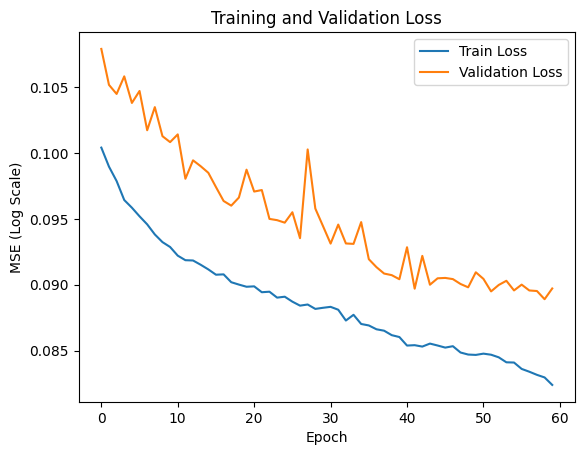

In [ ]:


plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (Log Scale)")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

The training and validation loss curves show a consistent decreasing trend across epochs, indicating that the model is learning effectively. The validation loss follows the same downward pattern as the training loss without significant divergence, suggesting that the model generalizes well and does not suffer from overfitting. Overall, the training process appears stable and convergent.

In [32]:
model.eval()
with torch.no_grad():
    y_pred_log = model(X_test_t).numpy().reshape(-1)

y_pred_real = np.expm1(y_pred_log)
y_test_real = np.expm1(y_test.to_numpy())

In [33]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test_real, y_pred_real)
print("MSE:", mse)

MSE: 4379162909.865511


In [34]:
rmse = np.sqrt(mse)
print("RMSE:", rmse)

RMSE: 66175.24393506616


In [35]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test_real, y_pred_real)
print("MAE:", mae)

MAE: 43981.340453155266


In [36]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test_real, y_pred_real)
print("R2:", r2)

R2: 0.6589265843753749


The deeper neural network significantly improved performance compared to the simple baseline model. The final R2 score on the test set reached 0.659, exceeding the minimum required threshold of 0.6. This indicates that the model explains approximately 65.9% of the variance in housing prices.

The RMSE was approximately 66,175 dollars, and the MAE was approximately 43,981 dollars. The training and validation loss curves demonstrated stable convergence without signs of overfitting. Overall, the deeper architecture successfully enhanced predictive performance.

# **2.4 Design and Train more complex Neural Network**

baseline model. The architecture consists of three hidden layers with 64, 32, and 16 neurons, respectively. Each hidden layer is followed by a ReLU activation function to introduce non-linearity into the model.

The final layer contains a single neuron that outputs the predicted (log-transformed) house price. By increasing the depth and number of neurons, the model gains higher representational capacity and can learn more complex relationships between input features and housing prices.

This deeper architecture led to a significant improvement in performance, achieving an R2

In [40]:
class DeepNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            
            nn.Linear(32, 16),
            nn.ReLU(),
            
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)

model = DeepNN(input_size)

In [41]:
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

In [42]:
total_params = sum(p.numel() for p in model.parameters())
print("Total Parameters:", total_params)

Total Parameters: 3521


The deeper neural network was trained for 150 epochs using mini-batch gradient descent. During each epoch, the model parameters were updated using the Adam optimizer based on the Mean Squared Error (MSE) loss.

For every batch in the training set, predictions were generated, the loss was computed, gradients were calculated through backpropagation, and the optimizer updated the weights. After completing the training phase of each epoch, the model was evaluated on the validation set without updating the parameters.

Both training and validation losses were recorded at each epoch to monitor the learning process. This allowed us to assess convergence behavior and ensure that the model was learning effectively without overfitting.

In [43]:
train_losses = []
val_losses = []

epochs = 150

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    
    for xb, yb in train_loader:
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * xb.size(0)
    
    train_loss = running_train_loss / len(train_loader.dataset)
    
    # Validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            pred = model(xb)
            loss = criterion(pred, yb)
            running_val_loss += loss.item() * xb.size(0)
    
    val_loss = running_val_loss / len(val_loader.dataset)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 01 | Train Loss: 29.7904 | Val Loss: 1.2486
Epoch 02 | Train Loss: 0.8714 | Val Loss: 0.3757
Epoch 03 | Train Loss: 0.2756 | Val Loss: 0.2206
Epoch 04 | Train Loss: 0.1680 | Val Loss: 0.1723
Epoch 05 | Train Loss: 0.1369 | Val Loss: 0.1446
Epoch 06 | Train Loss: 0.1212 | Val Loss: 0.1334
Epoch 07 | Train Loss: 0.1113 | Val Loss: 0.1176
Epoch 08 | Train Loss: 0.1037 | Val Loss: 0.1119
Epoch 09 | Train Loss: 0.0973 | Val Loss: 0.1148
Epoch 10 | Train Loss: 0.0929 | Val Loss: 0.0971
Epoch 11 | Train Loss: 0.0906 | Val Loss: 0.0985
Epoch 12 | Train Loss: 0.0885 | Val Loss: 0.0962
Epoch 13 | Train Loss: 0.0871 | Val Loss: 0.0954
Epoch 14 | Train Loss: 0.0857 | Val Loss: 0.0871
Epoch 15 | Train Loss: 0.0840 | Val Loss: 0.0852
Epoch 16 | Train Loss: 0.0845 | Val Loss: 0.0874
Epoch 17 | Train Loss: 0.0833 | Val Loss: 0.0870
Epoch 18 | Train Loss: 0.0857 | Val Loss: 0.0945
Epoch 19 | Train Loss: 0.0812 | Val Loss: 0.0892
Epoch 20 | Train Loss: 0.0796 | Val Loss: 0.0810
Epoch 21 | Train Lo

In [44]:
model.eval()

with torch.no_grad():
    y_pred_log = model(X_test_t).cpu().numpy().reshape(-1)

In [45]:
y_pred_real = np.expm1(y_pred_log)
y_test_real = np.expm1(y_test.to_numpy())

In [ ]:


r2 = r2_score(y_test_real, y_pred_real)
print("R²:", r2)

R²: 0.7627207878721209


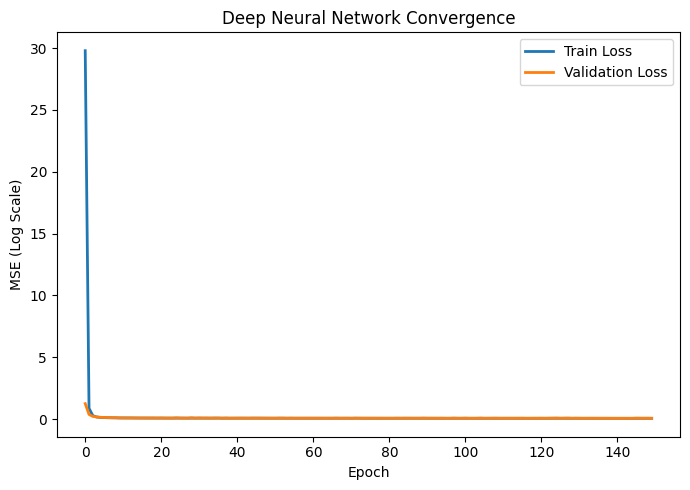

In [50]:
plt.figure(figsize=(7,5))

plt.plot(train_losses, linewidth=2, label="Train Loss")
plt.plot(val_losses, linewidth=2, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE (Log Scale)")
plt.title("Deep Neural Network Convergence")
plt.legend()
plt.tight_layout()
plt.show()

The deeper neural network significantly improved performance compared to the simple baseline model. The final R2 score on the test set reached 0.763, indicating that the model explains approximately 76.3% of the variance in housing prices.

The training and validation loss curves showed stable convergence without signs of overfitting, confirming that the model generalizes well to unseen data.

# **2.5 Comparison**

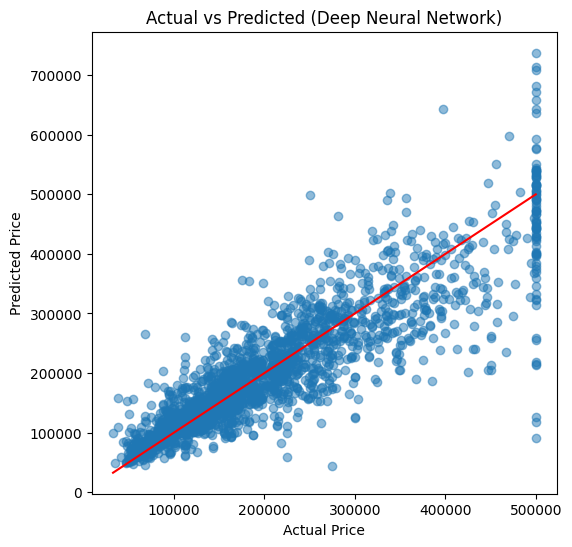

In [47]:

plt.figure(figsize=(6,6))
plt.scatter(y_test_real, y_pred_real, alpha=0.5)
plt.plot(
    [y_test_real.min(), y_test_real.max()],
    [y_test_real.min(), y_test_real.max()],
    color='red'
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted (Deep Neural Network)")
plt.show()

Model Comparison

Two neural network architectures were evaluated: a simple baseline model with one hidden layer (8 neurons) and a deeper network with three hidden layers (64–32–16 neurons).

The simple model achieved an R2 score of approximately 0.659, while the deeper network improved the R2 to 0.763. This represents a significant performance improvement, indicating that the deeper architecture is better able to capture nonlinear relationships in the housing data.

The training and validation loss curves also showed that the deeper network converged more effectively without signs of overfitting.

Compare plots for two mode:
The simple network showed a gradual decrease in training and validation loss but quickly reached a plateau, indicating limited learning capacity. Although it did not overfit, its performance was restricted due to the shallow architecture.

In contrast, the deep network achieved a larger reduction in both training and validation losses. After an initial high loss in the first epoch, it converged steadily and maintained a small gap between training and validation curves, indicating better generalization.

Overall, the deeper model demonstrated stronger convergence and improved learning performance

Overall, increasing model depth and capacity resulted in improved generalization and higher explanatory power.